# Drawing quantum circuits

This notebook demonstrates the text and Matplotlib circuit drawers, including parameterized and custom gates, multi-qubit operations, barriers, delays, measurements, and per-call style overrides.

In [1]:
from pathlib import Path

from mb_client.common import Parameter
from mb_client.circuit import Gate, QuantumCircuit
from mb_client.visualization.circuit import MatplotlibDrawer


## Build a representative circuit

Independent gates are placed in the same visual column. Operations sharing a wire remain ordered.

In [2]:
theta = Parameter("theta")
phi = Parameter("phi")

circuit = QuantumCircuit(3, 2, name="drawer_demo")
circuit.h(0)
circuit.rx(theta, 1)
circuit.rxy(theta, phi, 2)
circuit.cx(0, 1)
circuit.cz(1, 2)
circuit.barrier()
circuit.delay(20e-9, 0)
circuit.append(Gate("custom_entangler", 2, [0.25]), [1, 2])
circuit.measure(0, 0)
circuit.measure(2, 1)


CircuitInstruction(operation=<mb_client.circuit.operations.Measure object at 0x10e394510>, qubits=(Qubit(index=2),), clbits=(Clbit(index=1),))

## Text output

`print(circuit)`, `str(circuit)`, and `circuit.draw()` all use the default text drawer.

In [3]:
print(circuit)

         ┌───┐            ░ ┌────────────────────┐ ┌─┐
q_0: ────┤ H ├──────■─────░─┤ Delay(2e-08,drive) ├─┤M├──────
       ┌─┴───┴─┐  ┌─┴─┐   ░ └────┬───────────┬───┘ └╥┘
q_1: ──┤ Rx(θ) ├──┤ X ├─■─░──────┤           ├──────╫───────
     ┌─┴───────┴┐ └───┘ │ ░      │ Ent(0.25) │      ║  ┌─┐
q_2: ┤ Rxy(θ,φ) ├───────■─░──────┤           ├──────╫──┤M├──
     └──────────┘         ░      └───────────┘      ║  └╥┘
c: 2/═══════════════════════════════════════════════╩═══╩═══
                                                    0   1


In [4]:
str(circuit)

┌───┐            ░ ┌────────────────────┐ ┌─┐
q_0: ────┤ H ├──────■─────░─┤ Delay(2e-08,drive) ├─┤M├──────
       ┌─┴───┴─┐  ┌─┴─┐   ░ └────┬───────────┬───┘ └╥┘
q_1: ──┤ Rx(θ) ├──┤ X ├─■─░──────┤           ├──────╫───────
     ┌─┴───────┴┐ └───┘ │ ░      │ Ent(0.25) │      ║  ┌─┐
q_2: ┤ Rxy(θ,φ) ├───────■─░──────┤           ├──────╫──┤M├──
     └──────────┘         ░      └───────────┘      ║  └╥┘
c: 2/═══════════════════════════════════════════════╩═══╩═══
                                                    0   1

In [5]:
circuit.draw(format="text")

┌───┐            ░ ┌────────────────────┐ ┌─┐
q_0: ────┤ H ├──────■─────░─┤ Delay(2e-08,drive) ├─┤M├──────
       ┌─┴───┴─┐  ┌─┴─┐   ░ └────┬───────────┬───┘ └╥┘
q_1: ──┤ Rx(θ) ├──┤ X ├─■─░──────┤           ├──────╫───────
     ┌─┴───────┴┐ └───┘ │ ░      │ Ent(0.25) │      ║  ┌─┐
q_2: ┤ Rxy(θ,φ) ├───────■─░──────┤           ├──────╫──┤M├──
     └──────────┘         ░      └───────────┘      ║  └╥┘
c: 2/═══════════════════════════════════════════════╩═══╩═══
                                                    0   1

## Matplotlib output

The `mpl` format returns a figure. It does not call `show()` or save the image, so the caller remains in control. In a notebook, making the figure the final expression displays it inline.

In [6]:
%matplotlib inline

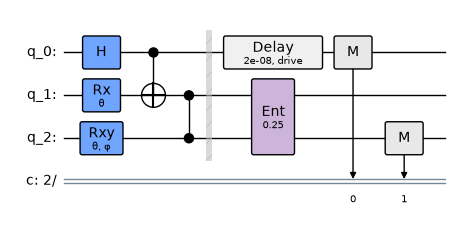

In [7]:
circuit.draw(format="mpl")

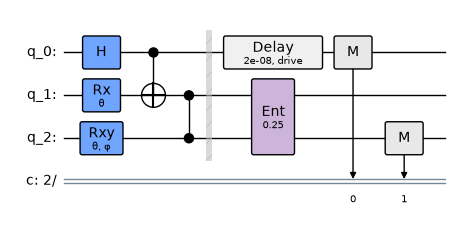

In [8]:
# Direct drawer usage returns the same output type.
MatplotlibDrawer(circuit).draw()

## Inline style overrides

Pass a partial dictionary to change only selected defaults for one draw. Nested dictionaries are deep-merged with the packaged JSON style.

In [9]:
text_style = {
    "text": {
        "box_left": "〈",
        "box_right": "〉",
        "control": "◆",
    },
    "gates": {
        "h": {"label": "Hadamard"},
        "custom_entangler": {"label": "E"},
    },
}
print(circuit.draw(style=text_style))

     ┌──────────┐         ░ ┌────────────────────┐ ┌─┐
q_0: ┤ Hadamard ├───◆─────░─┤ Delay(2e-08,drive) ├─┤M├──────
     └─┬───────┬┘ ┌─┴─┐   ░ └─────┬─────────┬────┘ └╥┘
q_1: ──┤ Rx(θ) ├──┤ X ├─◆─░───────┤         ├───────╫───────
     ┌─┴───────┴┐ └───┘ │ ░       │ E(0.25) │       ║  ┌─┐
q_2: ┤ Rxy(θ,φ) ├───────◆─░───────┤         ├───────╫──┤M├──
     └──────────┘         ░       └─────────┘       ║  └╥┘
c: 2/═══════════════════════════════════════════════╩═══╩═══
                                                    0   1


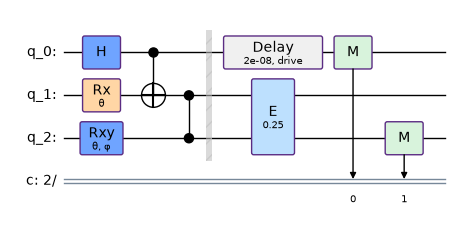

In [10]:
mpl_style = {
    "mpl": {
        "gate_facecolor": "#e8dcff",
        "gate_edgecolor": "#5b2c83",
        "measurement_facecolor": "#d8f3dc",
    },
    "gates": {
        "rx": {"facecolor": "#ffd6a5"},
        "custom_entangler": {"label": "E", "facecolor": "#bde0fe"},
    },
}
circuit.draw(format="mpl", style=mpl_style)

## Style overrides from JSON

A style path is useful for sharing a visual theme. The example JSON file sits next to this notebook and is also merged over the defaults.

        ┌─────┐           ┆ ┌────────────────────┐ ┌─┐
q_0: ───┤ Had ├─────◆─────┆─┤ Delay(2e-08,drive) ├─┤M├──────
       ┌┴─────┴┐  ┌─┴─┐   ┆ └────┬───────────┬───┘ └╥┘
q_1: ──┤ Rx(θ) ├──┤ X ├─◆─┆──────┤           ├──────╫───────
     ┌─┴───────┴┐ └───┘ │ ┆      │ Ent(0.25) │      ║  ┌─┐
q_2: ┤ Rxy(θ,φ) ├───────◆─┆──────┤           ├──────╫──┤M├──
     └──────────┘         ┆      └───────────┘      ║  └╥┘
c: 2/═══════════════════════════════════════════════╩═══╩═══
                                                    0   1


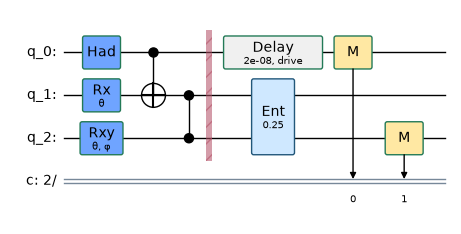

In [11]:
style_path = Path("circuit_style.json")
if not style_path.exists():  # Also works when launched from the repository root.
    style_path = Path("examples/visualization/circuit_style.json")

print(circuit.draw(style=style_path))
circuit.draw(format="mpl", style=style_path)

Each call loads a fresh copy of the default style. Overrides do not modify the circuit or affect later drawings.

In [12]:
print(circuit.draw())  # Back to the packaged defaults.

         ┌───┐            ░ ┌────────────────────┐ ┌─┐
q_0: ────┤ H ├──────■─────░─┤ Delay(2e-08,drive) ├─┤M├──────
       ┌─┴───┴─┐  ┌─┴─┐   ░ └────┬───────────┬───┘ └╥┘
q_1: ──┤ Rx(θ) ├──┤ X ├─■─░──────┤           ├──────╫───────
     ┌─┴───────┴┐ └───┘ │ ░      │ Ent(0.25) │      ║  ┌─┐
q_2: ┤ Rxy(θ,φ) ├───────■─░──────┤           ├──────╫──┤M├──
     └──────────┘         ░      └───────────┘      ║  └╥┘
c: 2/═══════════════════════════════════════════════╩═══╩═══
                                                    0   1
